In [2]:
%pip install wfdb


   ---- ----------------------------------- 1/9 [multidict]
   -------- ------------------------------- 2/9 [fsspec]
   -------- ------------------------------- 2/9 [fsspec]
   -------- ------------------------------- 2/9 [fsspec]
   -------- ------------------------------- 2/9 [fsspec]
   -------- ------------------------------- 2/9 [fsspec]
   -------- ------------------------------- 2/9 [fsspec]
   -------- ------------------------------- 2/9 [fsspec]
   -------- ------------------------------- 2/9 [fsspec]
   -------- ------------------------------- 2/9 [fsspec]
   -------- ------------------------------- 2/9 [fsspec]
   ----------------- ---------------------- 4/9 [aiohappyeyeballs]
   ---------------------- ----------------- 5/9 [yarl]
   -------------------------- ------------- 6/9 [aiosignal]
   ------------------------------- -------- 7/9 [aiohttp]
   ------------------------------- -------- 7/9 [aiohttp]
   ------------------------------- -------- 7/9 [aiohttp]
   ----------

In [3]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import wfdb

In [4]:
# To inspect which .hea contains ECG datas 
PCG_DIR = "../data/PCG"

PCG_DATASET = os.path.join(
    PCG_DIR,
    "extracted",
    "Rhd detection using phonocardiogram",
    "Rhd detection using phonocardiogram",
    "Dataset"
)

print("Dataset path:")
print(PCG_DATASET)

print("\nDataset exists:", os.path.exists(PCG_DATASET))

Dataset path:
../data/PCG\extracted\Rhd detection using phonocardiogram\Rhd detection using phonocardiogram\Dataset

Dataset exists: True


In [5]:
hea_files = [
    f for f in os.listdir(PCG_DATASET)
    if f.lower().endswith(".hea")
]

print("Total .hea files:", len(hea_files))

ecg_recordings = []
non_ecg_recordings = []

for file in hea_files:
    record_id = os.path.splitext(file)[0]
    
    try:
        record = wfdb.rdheader(os.path.join(PCG_DATASET, record_id))
        signal_names = record.sig_name
        
        if any("ecg" in str(name).lower() for name in signal_names):
            ecg_recordings.append((record_id, signal_names))
        else:
            non_ecg_recordings.append((record_id, signal_names))
            
    except Exception as e:
        print("Error reading:", file, "|", e)

print("\nECG recordings:", len(ecg_recordings))
print("Non-ECG recordings:", len(non_ecg_recordings))

print("\nFirst 10 ECG recordings:")
for item in ecg_recordings[:10]:
    print(item)

Total .hea files: 409

ECG recordings: 405
Non-ECG recordings: 4

First 10 ECG recordings:
('a0001', ['PCG', 'ECG'])
('a0002', ['PCG', 'ECG'])
('a0003', ['PCG', 'ECG'])
('a0004', ['PCG', 'ECG'])
('a0005', ['PCG', 'ECG'])
('a0006', ['PCG', 'ECG'])
('a0007', ['PCG', 'ECG'])
('a0008', ['PCG', 'ECG'])
('a0009', ['PCG', 'ECG'])
('a0010', ['PCG', 'ECG'])


In [6]:
print("Non-ECG recordings:")

for record_id, signal_names in non_ecg_recordings:
    print(record_id, "->", signal_names)

Non-ECG recordings:
a0041 -> ['PCG']
a0117 -> ['PCG']
a0220 -> ['PCG']
a0233 -> ['PCG']


In [7]:
record_id = "a0001"

record = wfdb.rdrecord(
    os.path.join(PCG_DATASET, record_id)
)

print("Record ID:", record_id)
print("Sampling frequency:", record.fs)
print("Number of samples:", record.sig_len)
print("Duration (seconds):", record.sig_len / record.fs)
print("Signal names:", record.sig_name)
print("Signal shape:", record.p_signal.shape)

Record ID: a0001
Sampling frequency: 2000
Number of samples: 71332
Duration (seconds): 35.666
Signal names: ['PCG', 'ECG']
Signal shape: (71332, 2)


In [8]:
ecg_signal = record.p_signal[:, 1]

print("ECG shape:", ecg_signal.shape)
print("ECG dtype:", ecg_signal.dtype)
print("ECG min:", np.min(ecg_signal))
print("ECG max:", np.max(ecg_signal))
print("ECG mean:", np.mean(ecg_signal))
print("ECG std:", np.std(ecg_signal))

ECG shape: (71332,)
ECG dtype: float64
ECG min: 0.0
ECG max: 4.972
ECG mean: 4.769216382549207
ECG std: 0.0758504139845178


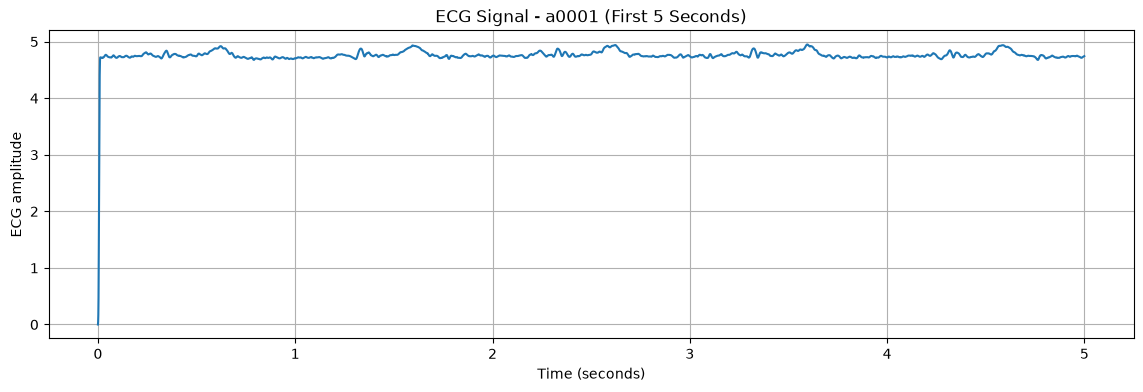

In [9]:
duration_sec = 5

samples = int(duration_sec * record.fs)

time = np.arange(samples) / record.fs

plt.figure(figsize=(14, 4))
plt.plot(time, ecg_signal[:samples])

plt.xlabel("Time (seconds)")
plt.ylabel("ECG amplitude")
plt.title("ECG Signal - a0001 (First 5 Seconds)")
plt.grid(True)
plt.show()

In [11]:
print("Signal names:", record.sig_name)
print("Units:", record.units)
print("ADC gains:", record.adc_gain)
print("ADC baselines:", record.baseline)
print("ADC resolutions:", record.adc_res)
print("Initial ECG values:", record.p_signal[:10, 1])

Signal names: ['PCG', 'ECG']
Units: ['mV', 'mV']
ADC gains: [1.0, 1000.0]
ADC baselines: [0, 0]
ADC resolutions: [16, 16]
Initial ECG values: [0.    0.015 0.046 0.094 0.176 0.301 0.478 0.71  1.    1.34 ]


In [12]:
ecg_centered = ecg_signal - np.mean(ecg_signal)

print("Original mean:", np.mean(ecg_signal))
print("Centered mean:", np.mean(ecg_centered))
print("Centered min:", np.min(ecg_centered))
print("Centered max:", np.max(ecg_centered))
print("Centered std:", np.std(ecg_centered))

Original mean: 4.769216382549207
Centered mean: -1.2750164046612014e-16
Centered min: -4.769216382549207
Centered max: 0.20278361745079376
Centered std: 0.0758504139845178


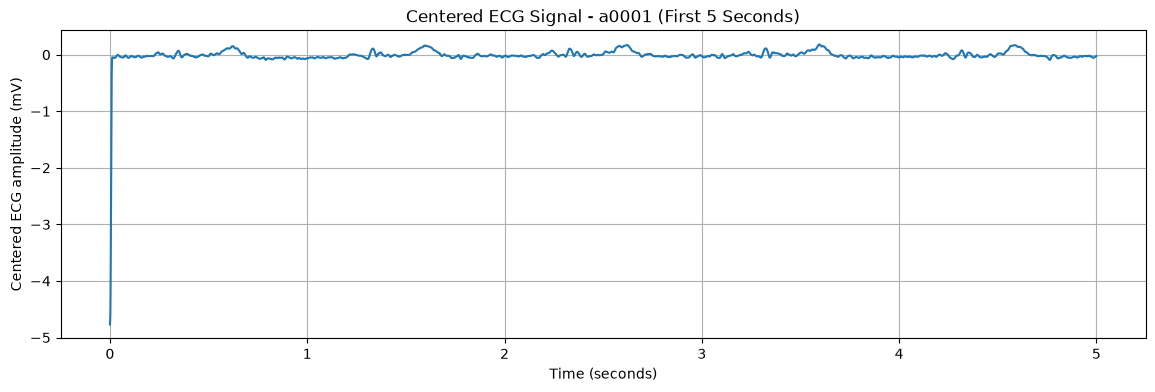

In [13]:
duration_sec = 5
samples = int(duration_sec * record.fs)

time = np.arange(samples) / record.fs

plt.figure(figsize=(14, 4))
plt.plot(time, ecg_centered[:samples])

plt.xlabel("Time (seconds)")
plt.ylabel("Centered ECG amplitude (mV)")
plt.title("Centered ECG Signal - a0001 (First 5 Seconds)")
plt.grid(True)
plt.show()

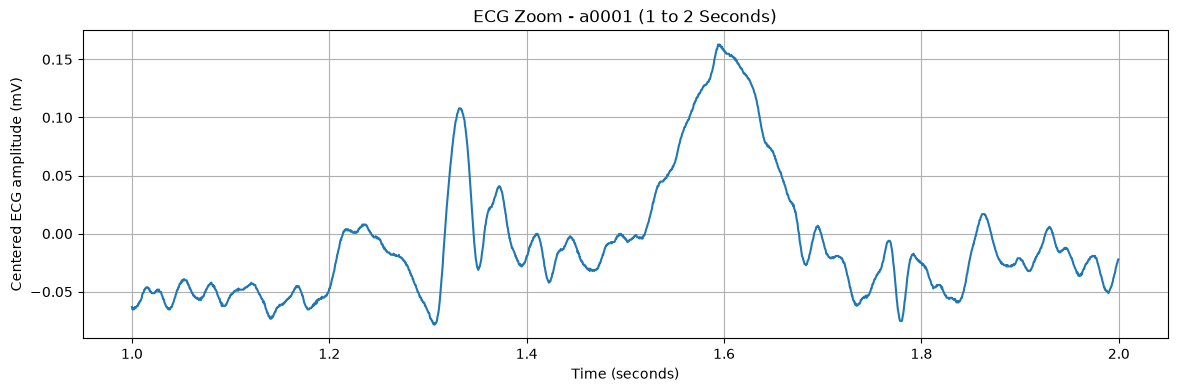

In [14]:
start_sec = 1
duration_sec = 1

start = int(start_sec * record.fs)
end = start + int(duration_sec * record.fs)

time_zoom = np.arange(start, end) / record.fs

plt.figure(figsize=(14, 4))
plt.plot(time_zoom, ecg_centered[start:end])

plt.xlabel("Time (seconds)")
plt.ylabel("Centered ECG amplitude (mV)")
plt.title("ECG Zoom - a0001 (1 to 2 Seconds)")
plt.grid(True)
plt.show()

In [15]:
print("Record comments:")
print(record.comments)

print("\nSampling frequency:", record.fs)
print("Signal names:", record.sig_name)
print("Units:", record.units)
print("Number of signals:", record.n_sig)
print("Signal length:", record.sig_len)

Record comments:
['Abnormal']

Sampling frequency: 2000
Signal names: ['PCG', 'ECG']
Units: ['mV', 'mV']
Number of signals: 2
Signal length: 71332


In [16]:
reference_file = os.path.join(PCG_DATASET, "REFERENCE.csv")

reference_df = pd.read_csv(
    reference_file,
    header=None,
    names=["recording_id", "label"]
)

print("Reference label for a0001:")
print(
    reference_df[
        reference_df["recording_id"] == "a0001"
    ]
)

print("\nHeader comment for a0001:")
print(record.comments)

Reference label for a0001:
  recording_id  label
0        a0001      1

Header comment for a0001:
['Abnormal']


In [17]:
label_check = []

for _, row in reference_df.iterrows():
    record_id = row["recording_id"]
    reference_label = row["label"]

    try:
        header = wfdb.rdheader(
            os.path.join(PCG_DATASET, record_id)
        )

        comment = header.comments[0] if header.comments else "Unknown"

        if "abnormal" in comment.lower():
            header_label = 1
        elif "normal" in comment.lower():
            header_label = -1
        else:
            header_label = None

        label_check.append(
            [record_id, reference_label, comment, header_label]
        )

    except Exception as e:
        print("Error:", record_id, "|", e)

label_check_df = pd.DataFrame(
    label_check,
    columns=["recording_id", "reference_label", "header_comment", "header_label"]
)

print("Total records checked:", len(label_check_df))

print("\nReference label counts:")
print(label_check_df["reference_label"].value_counts())

print("\nHeader-derived label counts:")
print(label_check_df["header_label"].value_counts(dropna=False))

print("\nMismatches:")
mismatches = label_check_df[
    label_check_df["reference_label"] != label_check_df["header_label"]
]

print(mismatches)

Total records checked: 409

Reference label counts:
reference_label
 1    292
-1    117
Name: count, dtype: int64

Header-derived label counts:
header_label
 1    292
-1    117
Name: count, dtype: int64

Mismatches:
Empty DataFrame
Columns: [recording_id, reference_label, header_comment, header_label]
Index: []


In [18]:
ecg_stats = []

for record_id, signal_names in ecg_recordings:
    try:
        header = wfdb.rdheader(
            os.path.join(PCG_DATASET, record_id)
        )

        ecg_index = [
            i for i, name in enumerate(header.sig_name)
            if "ecg" in str(name).lower()
        ][0]

        ecg_stats.append({
            "recording_id": record_id,
            "sampling_rate": header.fs,
            "duration_sec": header.sig_len / header.fs,
            "ecg_channel": header.sig_name[ecg_index]
        })

    except Exception as e:
        print("Error:", record_id, "|", e)

ecg_stats_df = pd.DataFrame(ecg_stats)

print("ECG recordings audited:", len(ecg_stats_df))

print("\nSampling rates:")
print(ecg_stats_df["sampling_rate"].value_counts())

print("\nDuration statistics:")
print(ecg_stats_df["duration_sec"].describe())

ECG recordings audited: 405

Sampling rates:
sampling_rate
2000    405
Name: count, dtype: int64

Duration statistics:
count    405.000000
mean      32.560778
std        5.308288
min        9.265000
25%       30.790000
50%       35.596500
75%       35.736000
max       36.502000
Name: duration_sec, dtype: float64


In [19]:
amplitude_stats = []

for record_id, signal_names in ecg_recordings:
    try:
        record_temp = wfdb.rdrecord(
            os.path.join(PCG_DATASET, record_id)
        )

        ecg_index = [
            i for i, name in enumerate(record_temp.sig_name)
            if "ecg" in str(name).lower()
        ][0]

        ecg_temp = record_temp.p_signal[:, ecg_index]

        amplitude_stats.append({
            "recording_id": record_id,
            "mean": np.mean(ecg_temp),
            "std": np.std(ecg_temp),
            "min": np.min(ecg_temp),
            "max": np.max(ecg_temp)
        })

    except Exception as e:
        print("Error:", record_id, "|", e)

amplitude_df = pd.DataFrame(amplitude_stats)

print("Recordings analyzed:", len(amplitude_df))

print("\nMean amplitude statistics:")
print(amplitude_df["mean"].describe())

print("\nStandard deviation statistics:")
print(amplitude_df["std"].describe())

print("\nMinimum amplitude statistics:")
print(amplitude_df["min"].describe())

print("\nMaximum amplitude statistics:")
print(amplitude_df["max"].describe())

Recordings analyzed: 405

Mean amplitude statistics:
count    390.000000
mean       2.407811
std        2.905740
min       -2.343833
25%        0.182176
50%        1.221132
75%        4.964012
max       21.124692
Name: mean, dtype: float64

Standard deviation statistics:
count    390.000000
mean       0.310458
std        0.878522
min        0.063238
25%        0.126654
50%        0.178024
75%        0.248184
max       10.763954
Name: std, dtype: float64

Minimum amplitude statistics:
count    390.000000
mean      -0.946662
std        2.992443
min      -31.067000
25%       -0.681250
50%       -0.002500
75%        0.001000
max        0.007000
Name: min, dtype: float64

Maximum amplitude statistics:
count    390.000000
mean       3.818249
std        3.779016
min       -0.006000
25%        0.939000
50%        4.884500
75%        5.612750
max       25.832000
Name: max, dtype: float64


**There are 390 valid amplitude-stat rows out of 405, so 15 recordings produced incomplete/NaN statistics.**

In [20]:
#Find the 15 recordings with missing statistics
missing_stats = amplitude_df[
    amplitude_df[["mean", "std", "min", "max"]].isna().any(axis=1)
]

print("Recordings with missing statistics:", len(missing_stats))
print()

print(missing_stats)

Recordings with missing statistics: 15

    recording_id  mean  std  min  max
12         a0013   NaN  NaN  NaN  NaN
88         a0090   NaN  NaN  NaN  NaN
111        a0113   NaN  NaN  NaN  NaN
134        a0137   NaN  NaN  NaN  NaN
224        a0228   NaN  NaN  NaN  NaN
268        a0273   NaN  NaN  NaN  NaN
271        a0276   NaN  NaN  NaN  NaN
274        a0279   NaN  NaN  NaN  NaN
286        a0291   NaN  NaN  NaN  NaN
290        a0295   NaN  NaN  NaN  NaN
300        a0305   NaN  NaN  NaN  NaN
328        a0333   NaN  NaN  NaN  NaN
339        a0344   NaN  NaN  NaN  NaN
361        a0366   NaN  NaN  NaN  NaN
362        a0367   NaN  NaN  NaN  NaN


In [21]:
record_id = "a0013"

problem_record = wfdb.rdrecord(
    os.path.join(PCG_DATASET, record_id)
)

ecg_index = [
    i for i, name in enumerate(problem_record.sig_name)
    if "ecg" in str(name).lower()
][0]

ecg_problem = problem_record.p_signal[:, ecg_index]

print("Record ID:", record_id)
print("Signal names:", problem_record.sig_name)
print("Sampling rate:", problem_record.fs)
print("Signal length:", problem_record.sig_len)
print("ECG shape:", ecg_problem.shape)

print("\nNaN count:", np.isnan(ecg_problem).sum())
print("Inf count:", np.isinf(ecg_problem).sum())
print("First 20 values:")
print(ecg_problem[:20])

Record ID: a0013
Signal names: ['PCG', 'ECG']
Sampling rate: 2000
Signal length: 71332
ECG shape: (71332,)

NaN count: 1
Inf count: 0
First 20 values:
[ -0.022  -0.121  -0.323  -0.684  -1.199  -1.971  -3.059  -4.412  -6.024
  -7.781  -9.639 -11.397 -13.045 -14.384 -15.329 -15.794 -15.743 -15.279
 -14.336 -13.079]


In [22]:
#Check NaN/Inf counts for all 15 problematic recordings
nan_audit = []

for record_id in missing_stats["recording_id"]:
    try:
        rec = wfdb.rdrecord(
            os.path.join(PCG_DATASET, record_id)
        )

        ecg_index = [
            i for i, name in enumerate(rec.sig_name)
            if "ecg" in str(name).lower()
        ][0]

        ecg = rec.p_signal[:, ecg_index]

        nan_audit.append({
            "recording_id": record_id,
            "samples": len(ecg),
            "nan_count": np.isnan(ecg).sum(),
            "inf_count": np.isinf(ecg).sum(),
            "finite_count": np.isfinite(ecg).sum()
        })

    except Exception as e:
        print("Error:", record_id, "|", e)

nan_audit_df = pd.DataFrame(nan_audit)

print(nan_audit_df.to_string(index=False))

recording_id  samples  nan_count  inf_count  finite_count
       a0013    71332          1          0         71331
       a0090    40821          6          0         40815
       a0113    72307         49          0         72258
       a0137    71611         11          0         71600
       a0228    54335         18          0         54317
       a0273    71611          4          0         71607
       a0276    71611         31          0         71580
       a0279    71193        172          0         71021
       a0291    71332         11          0         71321
       a0295    71611        176          0         71435
       a0305    71472        131          0         71341
       a0333    71472        120          0         71352
       a0344    71193        174          0         71019
       a0366    71332        158          0         71174
       a0367    71193          9          0         71184


In [23]:
#Check NAN's locations and consequtive gaps 
record_id = "a0295"

rec = wfdb.rdrecord(
    os.path.join(PCG_DATASET, record_id)
)

ecg_index = [
    i for i, name in enumerate(rec.sig_name)
    if "ecg" in str(name).lower()
][0]

ecg = rec.p_signal[:, ecg_index]

nan_positions = np.where(np.isnan(ecg))[0]

print("Record ID:", record_id)
print("Total NaN values:", len(nan_positions))

print("\nFirst 30 NaN positions:")
print(nan_positions[:30])

# Find consecutive NaN groups
if len(nan_positions) > 0:
    groups = []
    start = nan_positions[0]
    previous = nan_positions[0]

    for pos in nan_positions[1:]:
        if pos != previous + 1:
            groups.append((start, previous))
            start = pos
        previous = pos

    groups.append((start, previous))

    print("\nNumber of NaN groups:", len(groups))

    print("\nFirst 20 NaN groups:")
    for start, end in groups[:20]:
        print(
            f"Start: {start}, End: {end}, "
            f"Length: {end - start + 1}"
        )

Record ID: a0295
Total NaN values: 176

First 30 NaN positions:
[ 151  153  155 1256 1258 1927 1929 1932 1934 2232 2234 2236 2238 2534
 2535 2537 4284 4286 4290 4292 5897 5899 5901 5903 5905 6280 6282 6283
 6731 6733]

Number of NaN groups: 160

First 20 NaN groups:
Start: 151, End: 151, Length: 1
Start: 153, End: 153, Length: 1
Start: 155, End: 155, Length: 1
Start: 1256, End: 1256, Length: 1
Start: 1258, End: 1258, Length: 1
Start: 1927, End: 1927, Length: 1
Start: 1929, End: 1929, Length: 1
Start: 1932, End: 1932, Length: 1
Start: 1934, End: 1934, Length: 1
Start: 2232, End: 2232, Length: 1
Start: 2234, End: 2234, Length: 1
Start: 2236, End: 2236, Length: 1
Start: 2238, End: 2238, Length: 1
Start: 2534, End: 2535, Length: 2
Start: 2537, End: 2537, Length: 1
Start: 4284, End: 4284, Length: 1
Start: 4286, End: 4286, Length: 1
Start: 4290, End: 4290, Length: 1
Start: 4292, End: 4292, Length: 1
Start: 5897, End: 5897, Length: 1


In [24]:
#Check the maximum consecutive NAN gap
max_gap_summary = []

for record_id in missing_stats["recording_id"]:
    rec = wfdb.rdrecord(
        os.path.join(PCG_DATASET, record_id)
    )

    ecg_index = [
        i for i, name in enumerate(rec.sig_name)
        if "ecg" in str(name).lower()
    ][0]

    ecg = rec.p_signal[:, ecg_index]

    nan_positions = np.where(np.isnan(ecg))[0]

    if len(nan_positions) == 0:
        max_gap = 0
    else:
        gaps = []
        start = nan_positions[0]
        previous = nan_positions[0]

        for pos in nan_positions[1:]:
            if pos != previous + 1:
                gaps.append(previous - start + 1)
                start = pos
            previous = pos

        gaps.append(previous - start + 1)
        max_gap = max(gaps)

    max_gap_summary.append({
        "recording_id": record_id,
        "nan_count": len(nan_positions),
        "max_consecutive_nan": max_gap
    })

max_gap_df = pd.DataFrame(max_gap_summary)

print(max_gap_df.to_string(index=False))
print("\nOverall maximum consecutive NaN gap:",
      max_gap_df["max_consecutive_nan"].max())

recording_id  nan_count  max_consecutive_nan
       a0013          1                    1
       a0090          6                    2
       a0113         49                    2
       a0137         11                    2
       a0228         18                    1
       a0273          4                    2
       a0276         31                    4
       a0279        172                    2
       a0291         11                    2
       a0295        176                    2
       a0305        131                    4
       a0333        120                    2
       a0344        174                    5
       a0366        158                    2
       a0367          9                    2

Overall maximum consecutive NaN gap: 5


In [25]:
#Fill NaN values using linear interpolation
record_id = "a0295"

rec = wfdb.rdrecord(
    os.path.join(PCG_DATASET, record_id)
)

ecg_index = [
    i for i, name in enumerate(rec.sig_name)
    if "ecg" in str(name).lower()
][0]

ecg = rec.p_signal[:, ecg_index].copy()

print("NaNs before:", np.isnan(ecg).sum())

# Linear interpolation
ecg_series = pd.Series(ecg)
ecg_clean = ecg_series.interpolate(
    method="linear",
    limit_direction="both"
).to_numpy()

print("NaNs after:", np.isnan(ecg_clean).sum())

print("\nOriginal values around first NaN:")
first_nan = np.where(np.isnan(ecg))[0][0]
print(ecg[first_nan-2:first_nan+3])

print("\nInterpolated values:")
print(ecg_clean[first_nan-2:first_nan+3])

NaNs before: 176
NaNs after: 0

Original values around first NaN:
[-31.351 -32.327     nan -32.749     nan]

Interpolated values:
[-31.351 -32.327 -32.538 -32.749 -32.754]


In [27]:
# TO verify whether the interpolation works or not 
cleaning_results = []

for record_id, signal_names in ecg_recordings:
    try:
        rec = wfdb.rdrecord(
            os.path.join(PCG_DATASET, record_id)
        )

        ecg_index = [
            i for i, name in enumerate(rec.sig_name)
            if "ecg" in str(name).lower()
        ][0]

        ecg = rec.p_signal[:, ecg_index].copy()

        nan_before = np.isnan(ecg).sum()

        # Linear interpolation
        ecg_clean = pd.Series(ecg).interpolate(
            method="linear",
            limit_direction="both"
        ).to_numpy()

        nan_after = np.isnan(ecg_clean).sum()

        cleaning_results.append({
            "recording_id": record_id,
            "nan_before": nan_before,
            "nan_after": nan_after,
            "samples": len(ecg_clean)
        })

    except Exception as e:
        print("Error:", record_id, "|", e)

cleaning_df = pd.DataFrame(cleaning_results)

print("Total ECG recordings:", len(cleaning_df))
print("Recordings with NaNs before:",
      (cleaning_df["nan_before"] > 0).sum())
print("Recordings with NaNs after:",
      (cleaning_df["nan_after"] > 0).sum())
print("Total NaNs before:",
      cleaning_df["nan_before"].sum())
print("Total NaNs after:",
      cleaning_df["nan_after"].sum())

Total ECG recordings: 405
Recordings with NaNs before: 15
Recordings with NaNs after: 0
Total NaNs before: 1071
Total NaNs after: 0


In [28]:
#inspect the amplitude range after NaN cleaning for a few recordings
sample_ids = ["a0001", "a0013", "a0295"]

for record_id in sample_ids:

    rec = wfdb.rdrecord(
        os.path.join(PCG_DATASET, record_id)
    )

    ecg_index = [
        i for i, name in enumerate(rec.sig_name)
        if "ecg" in str(name).lower()
    ][0]

    ecg = rec.p_signal[:, ecg_index].copy()

    # Fill missing values
    ecg = pd.Series(ecg).interpolate(
        method="linear",
        limit_direction="both"
    ).to_numpy()

    print("\nRecord:", record_id)
    print("Min:", np.min(ecg))
    print("Max:", np.max(ecg))
    print("Mean:", np.mean(ecg))
    print("Std:", np.std(ecg))
    print("Range:", np.max(ecg) - np.min(ecg))


Record: a0001
Min: 0.0
Max: 4.972
Mean: 4.769216382549207
Std: 0.0758504139845178
Range: 4.972

Record: a0013
Min: -32.76
Max: 25.691
Mean: -0.3997207774911681
Std: 16.018312099247964
Range: 58.45099999999999

Record: a0295
Min: -32.767
Max: 16.281
Mean: -19.77385926743098
Std: 6.174878562188371
Range: 49.048


**Compare two common normalizations on sample ECGs
 check z-score normalization:**

$$ x_{norm}=\frac{x-\mu}{\sigma} $$

In [29]:
sample_ids = ["a0001", "a0013", "a0295"]

for record_id in sample_ids:

    rec = wfdb.rdrecord(
        os.path.join(PCG_DATASET, record_id)
    )

    ecg_index = [
        i for i, name in enumerate(rec.sig_name)
        if "ecg" in str(name).lower()
    ][0]

    ecg = rec.p_signal[:, ecg_index].copy()

    # Fill missing values
    ecg = pd.Series(ecg).interpolate(
        method="linear",
        limit_direction="both"
    ).to_numpy()

    # Z-score normalization
    mean = np.mean(ecg)
    std = np.std(ecg)

    ecg_z = (ecg - mean) / std

    print("\nRecord:", record_id)
    print("Original mean:", mean)
    print("Original std:", std)

    print("Normalized mean:", np.mean(ecg_z))
    print("Normalized std:", np.std(ecg_z))
    print("Normalized min:", np.min(ecg_z))
    print("Normalized max:", np.max(ecg_z))


Record: a0001
Original mean: 4.769216382549207
Original std: 0.0758504139845178
Normalized mean: -1.683021654152786e-15
Normalized std: 1.0
Normalized min: -62.87660319853593
Normalized max: 2.6734675105686954

Record: a0013
Original mean: -0.3997207774911681
Original std: 16.018312099247964
Normalized mean: 2.550032809322403e-17
Normalized std: 1.0
Normalized min: -2.0202053138937215
Normalized max: 1.6288058701713077

Record: a0295
Original mean: -19.77385926743098
Original std: 6.174878562188371
Normalized mean: -4.421357655314137e-16
Normalized std: 1.0
Normalized min: -2.104193726518286
Normalized max: 5.838958435265676


In [30]:
record_id = "a0001"

rec = wfdb.rdrecord(
    os.path.join(PCG_DATASET, record_id)
)

ecg_index = [
    i for i, name in enumerate(rec.sig_name)
    if "ecg" in str(name).lower()
][0]

ecg = rec.p_signal[:, ecg_index].copy()

# Fill missing values
ecg = pd.Series(ecg).interpolate(
    method="linear",
    limit_direction="both"
).to_numpy()

# Z-score normalization
ecg_z = (ecg - np.mean(ecg)) / np.std(ecg)

# Locate extreme value
min_index = np.argmin(ecg_z)
max_index = np.argmax(ecg_z)

print("Minimum normalized value:", ecg_z[min_index])
print("Minimum index:", min_index)
print("Minimum time (sec):", min_index / rec.fs)

print("\nMaximum normalized value:", ecg_z[max_index])
print("Maximum index:", max_index)
print("Maximum time (sec):", max_index / rec.fs)

# Show values around the minimum
start = max(0, min_index - 10)
end = min(len(ecg_z), min_index + 11)

print("\nValues around minimum:")
print(ecg_z[start:end])

Minimum normalized value: -62.87660319853593
Minimum index: 0
Minimum time (sec): 0.0

Maximum normalized value: 2.6734675105686954
Maximum index: 65413
Maximum time (sec): 32.7065

Values around minimum:
[-62.8766032  -62.67884554 -62.27014639 -61.63732189 -60.55624671
 -58.90826625 -56.57472593 -53.5160742  -49.69275953 -45.21025269
 -40.18720825]


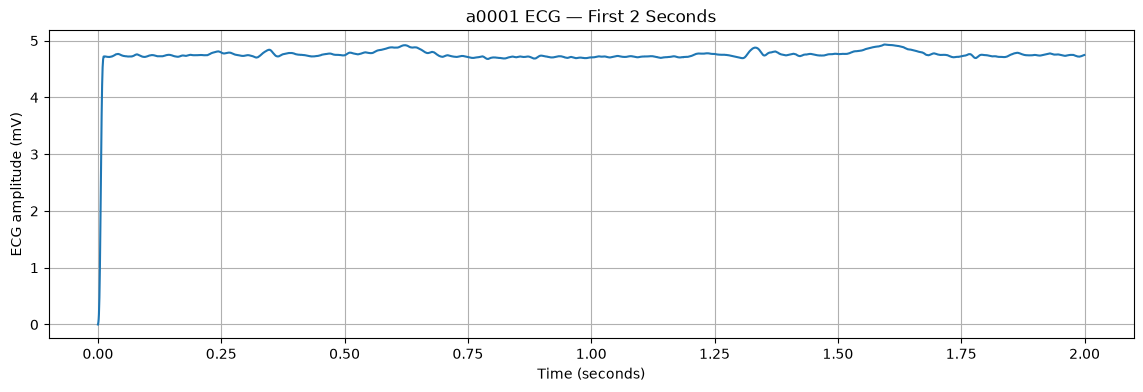

In [31]:
record_id = "a0001"

rec = wfdb.rdrecord(
    os.path.join(PCG_DATASET, record_id)
)

ecg_index = [
    i for i, name in enumerate(rec.sig_name)
    if "ecg" in str(name).lower()
][0]

ecg = rec.p_signal[:, ecg_index].copy()

# Fill missing values
ecg = pd.Series(ecg).interpolate(
    method="linear",
    limit_direction="both"
).to_numpy()

# First 2 seconds
duration_sec = 2
samples = int(duration_sec * rec.fs)

time = np.arange(samples) / rec.fs

plt.figure(figsize=(14, 4))
plt.plot(time, ecg[:samples])

plt.xlabel("Time (seconds)")
plt.ylabel("ECG amplitude (mV)")
plt.title("a0001 ECG — First 2 Seconds")
plt.grid(True)
plt.show()

The ECG has a large acquisition/startup step at the very beginning:

At t = 0, signal starts near 0 mV.


Within a few milliseconds it jumps to around 4.7 mV.


After that, the signal stays around a stable baseline with the ECG variations visible.

That explains why z-score normalization produced -62.88 at sample 0. The huge z-score is being caused by the startup transient, not by the normal ECG waveform.

Original:
  Mean: 4.769216382549207
  Std : 0.0758504139845178
  Min : 0.0
  Max : 4.972

After high-pass filtering:
  Mean: 0.021171753851578986
  Std : 0.2571633203865358
  Min : -1.0865621021715413
  Max : 3.5455321531627524


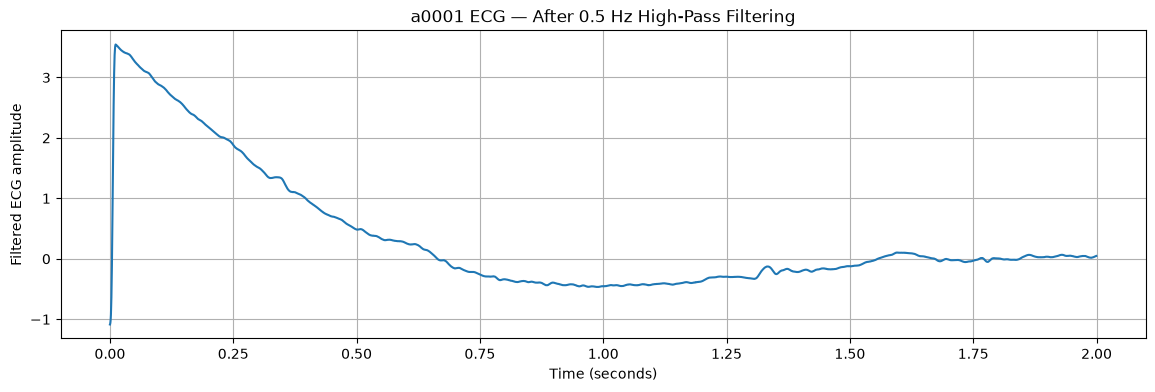

In [32]:
from scipy.signal import butter, filtfilt

record_id = "a0001"

rec = wfdb.rdrecord(
    os.path.join(PCG_DATASET, record_id)
)

ecg_index = [
    i for i, name in enumerate(rec.sig_name)
    if "ecg" in str(name).lower()
][0]

ecg = rec.p_signal[:, ecg_index].copy()

# Fill missing values
ecg = pd.Series(ecg).interpolate(
    method="linear",
    limit_direction="both"
).to_numpy()

# High-pass Butterworth filter
cutoff = 0.5
order = 3

b, a = butter(
    order,
    cutoff / (rec.fs / 2),
    btype="highpass"
)

ecg_filtered = filtfilt(b, a, ecg)

print("Original:")
print("  Mean:", np.mean(ecg))
print("  Std :", np.std(ecg))
print("  Min :", np.min(ecg))
print("  Max :", np.max(ecg))

print("\nAfter high-pass filtering:")
print("  Mean:", np.mean(ecg_filtered))
print("  Std :", np.std(ecg_filtered))
print("  Min :", np.min(ecg_filtered))
print("  Max :", np.max(ecg_filtered))

# Plot first 2 seconds
samples = int(2 * rec.fs)
time = np.arange(samples) / rec.fs

plt.figure(figsize=(14, 4))
plt.plot(time, ecg_filtered[:samples])

plt.xlabel("Time (seconds)")
plt.ylabel("Filtered ECG amplitude")
plt.title("a0001 ECG — After 0.5 Hz High-Pass Filtering")
plt.grid(True)
plt.show()

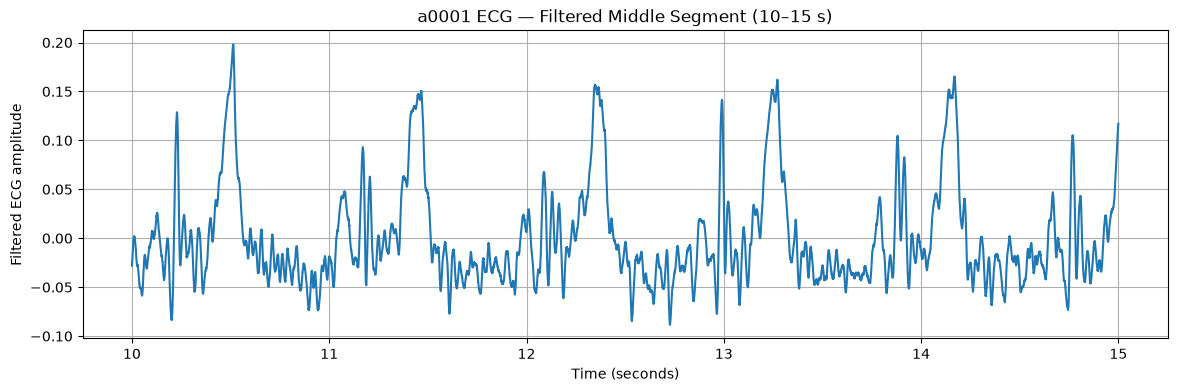

In [33]:
# Take a 5-second middle segment
start_sec = 10
duration_sec = 5

start = int(start_sec * rec.fs)
end = start + int(duration_sec * rec.fs)

time_middle = np.arange(start, end) / rec.fs

plt.figure(figsize=(14, 4))
plt.plot(time_middle, ecg_filtered[start:end])

plt.xlabel("Time (seconds)")
plt.ylabel("Filtered ECG amplitude")
plt.title("a0001 ECG — Filtered Middle Segment (10–15 s)")
plt.grid(True)
plt.show()

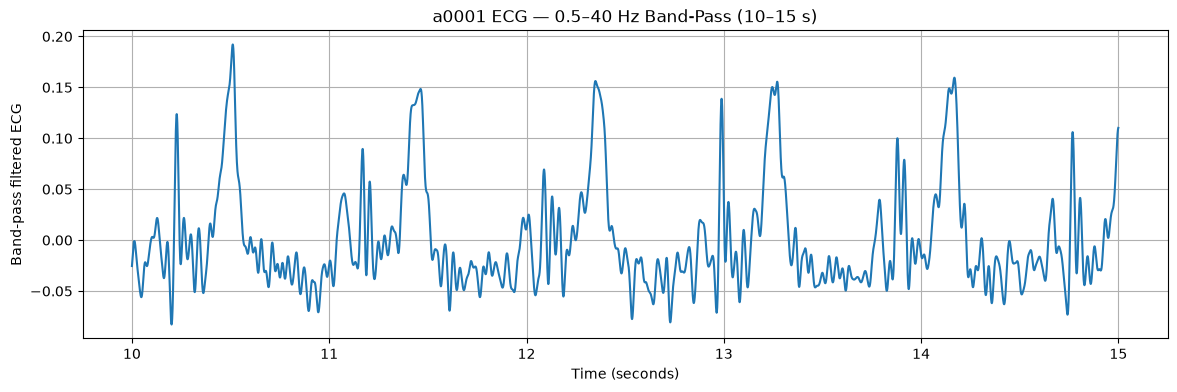

Mean: 0.027320852006339148
Std : 0.3282192716414348
Min : -0.5932447010915134
Max : 4.691209619084041


In [34]:
from scipy.signal import butter, filtfilt

# 0.5–40 Hz band-pass filter
lowcut = 0.5
highcut = 40.0
order = 3

nyquist = rec.fs / 2

b, a = butter(
    order,
    [lowcut / nyquist, highcut / nyquist],
    btype="bandpass"
)

ecg_bandpass = filtfilt(b, a, ecg)

# Plot the same middle section
start_sec = 10
duration_sec = 5

start = int(start_sec * rec.fs)
end = start + int(duration_sec * rec.fs)

time_middle = np.arange(start, end) / rec.fs

plt.figure(figsize=(14, 4))
plt.plot(time_middle, ecg_bandpass[start:end])

plt.xlabel("Time (seconds)")
plt.ylabel("Band-pass filtered ECG")
plt.title("a0001 ECG — 0.5–40 Hz Band-Pass (10–15 s)")
plt.grid(True)
plt.show()

print("Mean:", np.mean(ecg_bandpass))
print("Std :", np.std(ecg_bandpass))
print("Min :", np.min(ecg_bandpass))
print("Max :", np.max(ecg_bandpass))

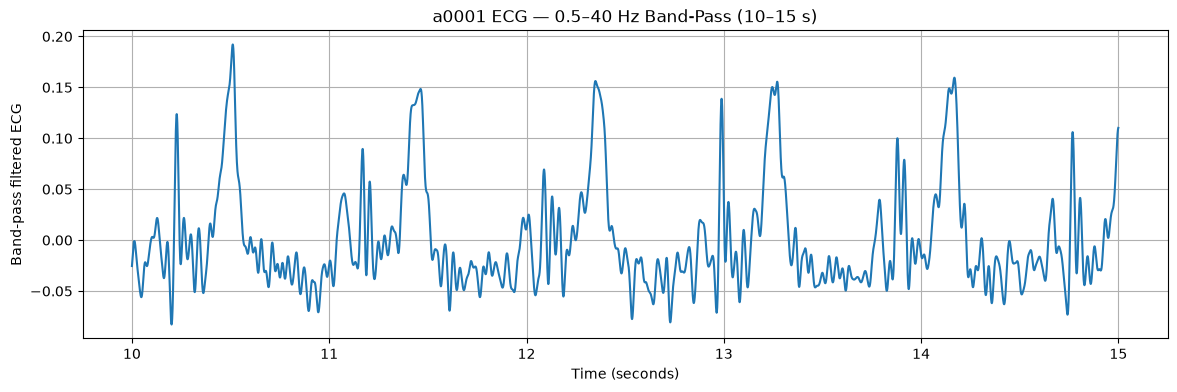

Middle segment mean: -0.00010260541973450082
Middle segment std: 0.05092909300524875
Middle segment min: -0.08284578823265074
Middle segment max: 0.19208088550377841


In [35]:
start_sec = 10
duration_sec = 5

start = int(start_sec * rec.fs)
end = start + int(duration_sec * rec.fs)

time_middle = np.arange(start, end) / rec.fs

plt.figure(figsize=(14, 4))
plt.plot(time_middle, ecg_bandpass[start:end])

plt.xlabel("Time (seconds)")
plt.ylabel("Band-pass filtered ECG")
plt.title("a0001 ECG — 0.5–40 Hz Band-Pass (10–15 s)")
plt.grid(True)
plt.show()

print("Middle segment mean:",
      np.mean(ecg_bandpass[start:end]))

print("Middle segment std:",
      np.std(ecg_bandpass[start:end]))

print("Middle segment min:",
      np.min(ecg_bandpass[start:end]))

print("Middle segment max:",
      np.max(ecg_bandpass[start:end]))

In [36]:
# Z-score normalization after band-pass filtering
filtered_mean = np.mean(ecg_bandpass)
filtered_std = np.std(ecg_bandpass)

ecg_normalized = (
    (ecg_bandpass - filtered_mean) / filtered_std
)

print("After band-pass filtering + z-score normalization:")

print("Mean:", np.mean(ecg_normalized))
print("Std :", np.std(ecg_normalized))
print("Min :", np.min(ecg_normalized))
print("Max :", np.max(ecg_normalized))

# Check the middle segment
middle_normalized = ecg_normalized[start:end]

print("\nMiddle segment:")
print("Mean:", np.mean(middle_normalized))
print("Std :", np.std(middle_normalized))
print("Min :", np.min(middle_normalized))
print("Max :", np.max(middle_normalized))

After band-pass filtering + z-score normalization:
Mean: 6.3750820233060076e-18
Std : 1.0
Min : -1.8907041929451154
Max : 14.209673745704965

Middle segment:
Mean: -0.08355224630451492
Std : 0.15516789355649585
Min : -0.3356495177386845
Max : 0.5019815950278276


In [37]:
sample_ids = ["a0001", "a0013", "a0295"]

for record_id in sample_ids:

    rec = wfdb.rdrecord(
        os.path.join(PCG_DATASET, record_id)
    )

    ecg_index = [
        i for i, name in enumerate(rec.sig_name)
        if "ecg" in str(name).lower()
    ][0]

    ecg = rec.p_signal[:, ecg_index].copy()

    # Fill NaNs
    ecg = pd.Series(ecg).interpolate(
        method="linear",
        limit_direction="both"
    ).to_numpy()

    # 0.5–40 Hz band-pass
    nyquist = rec.fs / 2
    b, a = butter(
        3,
        [0.5 / nyquist, 40.0 / nyquist],
        btype="bandpass"
    )

    filtered = filtfilt(b, a, ecg)

    # First 1 second
    first_end = int(1 * rec.fs)
    first_sec = filtered[:first_end]

    # Middle 5 seconds
    middle_start = int(10 * rec.fs)
    middle_end = middle_start + int(5 * rec.fs)
    middle_sec = filtered[middle_start:middle_end]

    print("\nRecord:", record_id)

    print("First 1 sec:")
    print("  Mean:", np.mean(first_sec))
    print("  Std :", np.std(first_sec))
    print("  Min :", np.min(first_sec))
    print("  Max :", np.max(first_sec))

    print("Middle 5 sec:")
    print("  Mean:", np.mean(middle_sec))
    print("  Std :", np.std(middle_sec))
    print("  Min :", np.min(middle_sec))
    print("  Max :", np.max(middle_sec))


Record: a0001
First 1 sec:
  Mean: 1.1201842718781245
  Std : 1.5610169562183573
  Min : -0.5932447010915134
  Max : 4.691209619084041
Middle 5 sec:
  Mean: -0.00010260541973450082
  Std : 0.05092909300524875
  Min : -0.08284578823265074
  Max : 0.19208088550377841

Record: a0013
First 1 sec:
  Mean: -2.1056959916428046
  Std : 16.386732611335887
  Min : -29.291355056388877
  Max : 25.2828152993934
Middle 5 sec:
  Mean: 0.15855782958775044
  Std : 15.429329718688999
  Min : -28.014757908706592
  Max : 30.312681971924604

Record: a0295
First 1 sec:
  Mean: -3.9813916519448127
  Std : 7.593065614603468
  Min : -22.189624231150074
  Max : 20.866813389205248
Middle 5 sec:
  Mean: -0.05048131512050881
  Std : 4.712053831636543
  Min : -11.71723138357234
  Max : 18.8236599691591


In [38]:
startup_stats = []

for record_id, signal_names in ecg_recordings:

    try:
        rec = wfdb.rdrecord(
            os.path.join(PCG_DATASET, record_id)
        )

        ecg_index = [
            i for i, name in enumerate(rec.sig_name)
            if "ecg" in str(name).lower()
        ][0]

        ecg = rec.p_signal[:, ecg_index].copy()

        # Fill NaNs
        ecg = pd.Series(ecg).interpolate(
            method="linear",
            limit_direction="both"
        ).to_numpy()

        # 0.5–40 Hz band-pass
        nyquist = rec.fs / 2

        b, a = butter(
            3,
            [0.5 / nyquist, 40.0 / nyquist],
            btype="bandpass"
        )

        filtered = filtfilt(b, a, ecg)

        # First 1 second
        first_end = min(int(1 * rec.fs), len(filtered))
        first_sec = filtered[:first_end]

        # Middle 5 seconds
        middle_start = int(10 * rec.fs)
        middle_end = min(middle_start + int(5 * rec.fs), len(filtered))

        if middle_end > middle_start:
            middle_sec = filtered[middle_start:middle_end]

            startup_stats.append({
                "recording_id": record_id,
                "startup_std": np.std(first_sec),
                "middle_std": np.std(middle_sec),
                "startup_abs_mean": np.mean(np.abs(first_sec)),
                "middle_abs_mean": np.mean(np.abs(middle_sec))
            })

    except Exception as e:
        print("Error:", record_id, "|", e)

startup_df = pd.DataFrame(startup_stats)

print("Recordings analyzed:", len(startup_df))

print("\nStartup STD:")
print(startup_df["startup_std"].describe())

print("\nMiddle STD:")
print(startup_df["middle_std"].describe())

print("\nStartup/Middle STD ratio:")
ratio = (
    startup_df["startup_std"] /
    startup_df["middle_std"].replace(0, np.nan)
)

print(ratio.describe())

Recordings analyzed: 404

Startup STD:
count    404.000000
mean       1.330171
std        2.043101
min        0.050048
25%        0.231412
50%        1.006300
75%        1.636977
max       16.386733
Name: startup_std, dtype: float64

Middle STD:
count    404.000000
mean       0.502711
std        1.791628
min        0.031577
25%        0.102194
50%        0.159635
75%        0.222080
max       15.429330
Name: middle_std, dtype: float64

Startup/Middle STD ratio:
count    404.000000
mean       7.982663
std        9.444045
min        0.229501
25%        1.230545
50%        3.363057
75%       11.815146
max       51.804763
dtype: float64


In [39]:
sample_ids = ["a0001", "a0013", "a0295"]

for record_id in sample_ids:

    rec = wfdb.rdrecord(
        os.path.join(PCG_DATASET, record_id)
    )

    ecg_index = [
        i for i, name in enumerate(rec.sig_name)
        if "ecg" in str(name).lower()
    ][0]

    ecg = rec.p_signal[:, ecg_index].copy()

    # Fill NaNs
    ecg = pd.Series(ecg).interpolate(
        method="linear",
        limit_direction="both"
    ).to_numpy()

    # 0.5–40 Hz band-pass
    nyquist = rec.fs / 2

    b, a = butter(
        3,
        [0.5 / nyquist, 40.0 / nyquist],
        btype="bandpass"
    )

    filtered = filtfilt(b, a, ecg)

    # Robust normalization using median and MAD
    median = np.median(filtered)
    mad = np.median(np.abs(filtered - median))

    robust_normalized = (
        (filtered - median) / (1.4826 * mad)
    )

    print("\nRecord:", record_id)
    print("Median:", median)
    print("MAD:", mad)

    print("Normalized mean:", np.mean(robust_normalized))
    print("Normalized median:", np.median(robust_normalized))
    print("Normalized std:", np.std(robust_normalized))
    print("Normalized min:", np.min(robust_normalized))
    print("Normalized max:", np.max(robust_normalized))


Record: a0001
Median: -0.015220313264564835
MAD: 0.022418920035769216
Normalized mean: 1.2798842596704445
Normalized median: 0.0
Normalized std: 9.874733727185554
Normalized min: -17.39031620253583
Normalized max: 141.59662884868635

Record: a0013
Median: -3.2804491745286617
MAD: 11.920325095168208
Normalized mean: 0.1837099810976691
Normalized median: 0.0
Normalized std: 0.8626817547469888
Normalized min: -1.5838236642311576
Normalized max: 1.9497603562055414

Record: a0295
Median: -0.5831699444636562
MAD: 3.3524149268887182
Normalized mean: 0.09963645459779116
Normalized median: 0.0
Normalized std: 1.08400798430668
Normalized min: -4.34712112887189
Normalized max: 5.3342803322001116


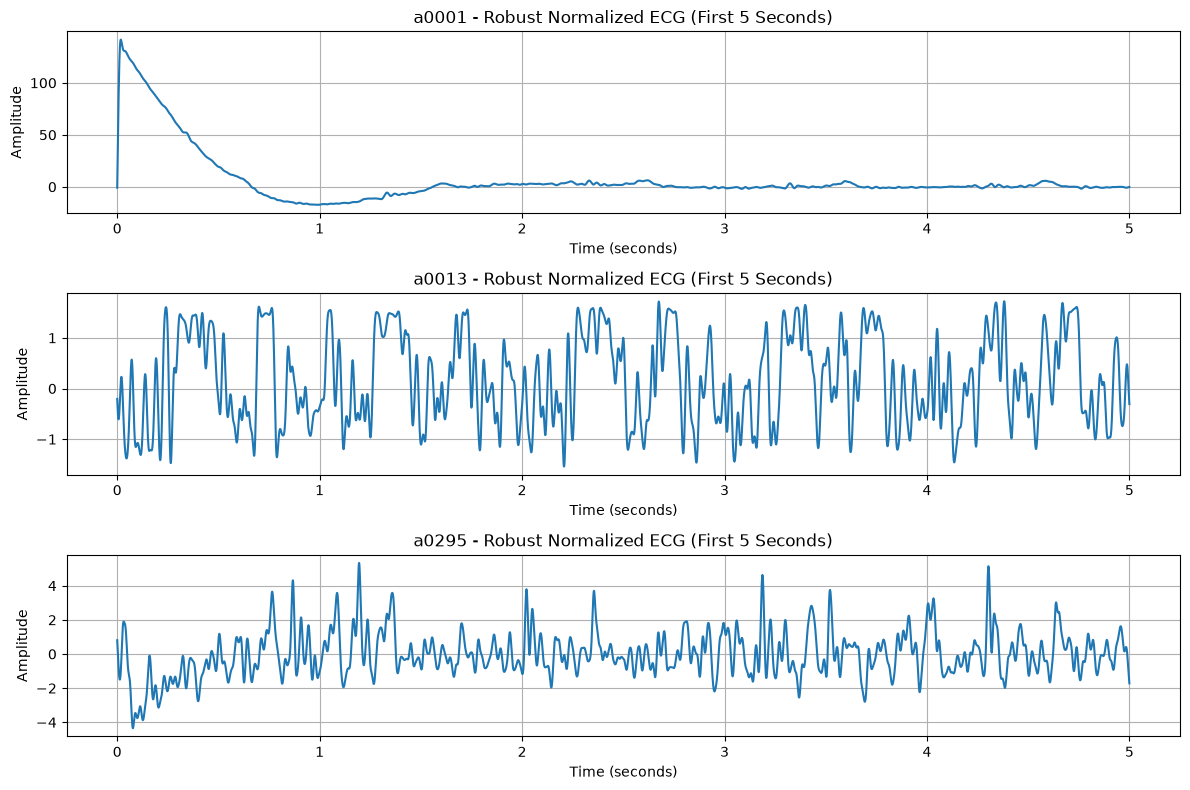

In [40]:
# Cell 37: Check robust-normalized ECG for startup/outlier effects

sample_ids = ["a0001", "a0013", "a0295"]

fig, axes = plt.subplots(len(sample_ids), 1, figsize=(12, 8))

for ax, record_id in zip(axes, sample_ids):

    rec = wfdb.rdrecord(os.path.join(PCG_DATASET, record_id))

    # ECG channel
    ecg_index = [
        i for i, name in enumerate(rec.sig_name)
        if "ecg" in str(name).lower()
    ][0]

    ecg = rec.p_signal[:, ecg_index].copy()

    # Fill missing values
    ecg = pd.Series(ecg).interpolate(
        method="linear",
        limit_direction="both"
    ).to_numpy()

    # Band-pass filter
    nyquist = rec.fs / 2
    b, a = butter(
        3,
        [0.5 / nyquist, 40.0 / nyquist],
        btype="bandpass"
    )

    filtered = filtfilt(b, a, ecg)

    # Robust normalization
    median = np.median(filtered)
    mad = np.median(np.abs(filtered - median))

    robust_normalized = (
        (filtered - median) /
        (1.4826 * mad)
    )

    # Plot first 5 seconds
    time = np.arange(len(robust_normalized)) / rec.fs
    mask = time <= 5

    ax.plot(time[mask], robust_normalized[mask])
    ax.set_title(f"{record_id} - Robust Normalized ECG (First 5 Seconds)")
    ax.set_xlabel("Time (seconds)")
    ax.set_ylabel("Amplitude")

    ax.grid(True)

plt.tight_layout()
plt.show()

In [41]:
# Cell 38: Compare startup and stable-region statistics

sample_ids = ["a0001", "a0013", "a0295"]

for record_id in sample_ids:

    rec = wfdb.rdrecord(os.path.join(PCG_DATASET, record_id))

    ecg_index = [
        i for i, name in enumerate(rec.sig_name)
        if "ecg" in str(name).lower()
    ][0]

    ecg = rec.p_signal[:, ecg_index].copy()

    # Fill missing values
    ecg = pd.Series(ecg).interpolate(
        method="linear",
        limit_direction="both"
    ).to_numpy()

    # Band-pass filter
    nyquist = rec.fs / 2
    b, a = butter(
        3,
        [0.5 / nyquist, 40.0 / nyquist],
        btype="bandpass"
    )

    filtered = filtfilt(b, a, ecg)

    # First 1 second
    startup = filtered[:int(rec.fs * 1)]

    # Stable middle region: 10–15 seconds
    start = int(rec.fs * 10)
    end = int(rec.fs * 15)
    middle = filtered[start:end]

    print(f"\nRecord: {record_id}")
    print(f"Startup 1-sec std : {np.std(startup):.4f}")
    print(f"Middle 10-15s std : {np.std(middle):.4f}")
    print(f"Std ratio         : {np.std(startup) / np.std(middle):.2f}")


Record: a0001
Startup 1-sec std : 1.5610
Middle 10-15s std : 0.0509
Std ratio         : 30.65

Record: a0013
Startup 1-sec std : 16.3867
Middle 10-15s std : 15.4293
Std ratio         : 1.06

Record: a0295
Startup 1-sec std : 7.5931
Middle 10-15s std : 4.7121
Std ratio         : 1.61


In [42]:
# Cell 39: Check how many samples are extreme after band-pass filtering

sample_ids = ["a0001", "a0013", "a0295"]

for record_id in sample_ids:

    rec = wfdb.rdrecord(os.path.join(PCG_DATASET, record_id))

    ecg_index = [
        i for i, name in enumerate(rec.sig_name)
        if "ecg" in str(name).lower()
    ][0]

    ecg = rec.p_signal[:, ecg_index].copy()

    # Fill missing values
    ecg = pd.Series(ecg).interpolate(
        method="linear",
        limit_direction="both"
    ).to_numpy()

    # Band-pass filter
    nyquist = rec.fs / 2
    b, a = butter(
        3,
        [0.5 / nyquist, 40.0 / nyquist],
        btype="bandpass"
    )

    filtered = filtfilt(b, a, ecg)

    # Robust statistics
    median = np.median(filtered)
    mad = np.median(np.abs(filtered - median))
    robust_std = 1.4826 * mad

    robust_z = (filtered - median) / robust_std

    # Extreme thresholds
    thresholds = [3, 5, 10]

    print(f"\nRecord: {record_id}")
    print(f"Total samples: {len(filtered)}")

    for threshold in thresholds:
        count = np.sum(np.abs(robust_z) > threshold)
        percentage = (count / len(robust_z)) * 100

        print(
            f"|z| > {threshold}: "
            f"{count} samples ({percentage:.4f}%)"
        )


Record: a0001
Total samples: 71332
|z| > 3: 9408 samples (13.1890%)
|z| > 5: 3980 samples (5.5795%)
|z| > 10: 2309 samples (3.2370%)

Record: a0013
Total samples: 71332
|z| > 3: 0 samples (0.0000%)
|z| > 5: 0 samples (0.0000%)
|z| > 10: 0 samples (0.0000%)

Record: a0295
Total samples: 71611
|z| > 3: 1236 samples (1.7260%)
|z| > 5: 22 samples (0.0307%)
|z| > 10: 0 samples (0.0000%)


In [43]:
# Cell 40: Dataset-wide robust z-score outlier audit

results = []

hea_files = [
    f for f in os.listdir(PCG_DATASET)
    if f.endswith(".hea")
]

for hea_file in hea_files:

    record_id = hea_file.replace(".hea", "")

    rec = wfdb.rdrecord(
        os.path.join(PCG_DATASET, record_id)
    )

    # Find ECG channel
    ecg_indices = [
        i for i, name in enumerate(rec.sig_name)
        if "ecg" in str(name).lower()
    ]

    if not ecg_indices:
        continue

    ecg = rec.p_signal[:, ecg_indices[0]].copy()

    # Fill short missing gaps
    ecg = pd.Series(ecg).interpolate(
        method="linear",
        limit_direction="both"
    ).to_numpy()

    # Band-pass filter
    nyquist = rec.fs / 2

    b, a = butter(
        3,
        [0.5 / nyquist, 40.0 / nyquist],
        btype="bandpass"
    )

    filtered = filtfilt(b, a, ecg)

    # Robust normalization
    median = np.median(filtered)
    mad = np.median(np.abs(filtered - median))

    if mad == 0:
        continue

    robust_std = 1.4826 * mad
    robust_z = (filtered - median) / robust_std

    total = len(robust_z)

    count_3 = np.sum(np.abs(robust_z) > 3)
    count_5 = np.sum(np.abs(robust_z) > 5)
    count_10 = np.sum(np.abs(robust_z) > 10)

    results.append({
        "recording_id": record_id,
        "pct_gt3": 100 * count_3 / total,
        "pct_gt5": 100 * count_5 / total,
        "pct_gt10": 100 * count_10 / total
    })

outlier_df = pd.DataFrame(results)

print("ECG recordings analyzed:", len(outlier_df))

print("\nPercentage of recordings with:")
print(
    "More than 1% samples having |z| > 10:",
    np.sum(outlier_df["pct_gt10"] > 1)
)

print(
    "More than 5% samples having |z| > 5:",
    np.sum(outlier_df["pct_gt5"] > 5)
)

print(
    "More than 10% samples having |z| > 3:",
    np.sum(outlier_df["pct_gt3"] > 10)
)

print("\nDataset statistics:")
print(outlier_df[["pct_gt3", "pct_gt5", "pct_gt10"]].describe())

ECG recordings analyzed: 405

Percentage of recordings with:
More than 1% samples having |z| > 10: 253
More than 5% samples having |z| > 5: 259
More than 10% samples having |z| > 3: 293

Dataset statistics:
          pct_gt3     pct_gt5    pct_gt10
count  405.000000  405.000000  405.000000
mean    13.084795    6.512200    1.947778
std      5.333078    3.888330    1.800135
min      0.000000    0.000000    0.000000
25%      9.484175    3.634297    0.335707
50%     12.879443    6.304954    1.582438
75%     16.882829    8.515359    3.169606
max     31.349129   23.722648   10.211589


In [44]:
# Cell 41: Check ECG duration and sample counts for segmentation planning

duration_stats = []

for record_id in outlier_df["recording_id"]:

    rec = wfdb.rdrecord(
        os.path.join(PCG_DATASET, record_id)
    )

    duration = len(rec.p_signal) / rec.fs

    duration_stats.append({
        "recording_id": record_id,
        "sample_rate": rec.fs,
        "samples": len(rec.p_signal),
        "duration_sec": duration
    })

duration_df = pd.DataFrame(duration_stats)

print("Sample rates:")
print(duration_df["sample_rate"].value_counts())

print("\nDuration statistics:")
print(duration_df["duration_sec"].describe())

print("\nFirst 10 recordings:")
print(duration_df.head(10))

Sample rates:
sample_rate
2000    405
Name: count, dtype: int64

Duration statistics:
count    405.000000
mean      32.560778
std        5.308288
min        9.265000
25%       30.790000
50%       35.596500
75%       35.736000
max       36.502000
Name: duration_sec, dtype: float64

First 10 recordings:
  recording_id  sample_rate  samples  duration_sec
0        a0001         2000    71332       35.6660
1        a0002         2000    41657       20.8285
2        a0003         2000    61440       30.7200
3        a0004         2000    71193       35.5965
4        a0005         2000    71332       35.6660
5        a0006         2000    41518       20.7590
6        a0007         2000    71332       35.6660
7        a0008         2000    71611       35.8055
8        a0009         2000    71611       35.8055
9        a0010         2000    71472       35.7360


In [45]:
# Cell 42: Test ECG segmentation on sample recordings

sample_ids = ["a0001", "a0013", "a0295"]

segment_duration = 2.0

for record_id in sample_ids:

    rec = wfdb.rdrecord(
        os.path.join(PCG_DATASET, record_id)
    )

    ecg_index = [
        i for i, name in enumerate(rec.sig_name)
        if "ecg" in str(name).lower()
    ][0]

    ecg = rec.p_signal[:, ecg_index].copy()

    # Fill missing values
    ecg = pd.Series(ecg).interpolate(
        method="linear",
        limit_direction="both"
    ).to_numpy()

    # Band-pass filter
    nyquist = rec.fs / 2

    b, a = butter(
        3,
        [0.5 / nyquist, 40.0 / nyquist],
        btype="bandpass"
    )

    filtered = filtfilt(b, a, ecg)

    # Robust normalization
    median = np.median(filtered)
    mad = np.median(np.abs(filtered - median))

    robust_normalized = (
        (filtered - median) /
        (1.4826 * mad)
    )

    # 2-second segmentation
    segment_samples = int(segment_duration * rec.fs)

    num_segments = len(robust_normalized) // segment_samples

    segments = []

    for i in range(num_segments):
        start = i * segment_samples
        end = start + segment_samples

        segments.append(
            robust_normalized[start:end]
        )

    segments = np.array(segments)

    print(f"\nRecord: {record_id}")
    print(f"Original samples : {len(ecg)}")
    print(f"Duration         : {len(ecg) / rec.fs:.3f} sec")
    print(f"Segment samples  : {segment_samples}")
    print(f"Number segments  : {len(segments)}")
    print(f"Segment shape    : {segments.shape}")
    print(f"Unused samples   : {len(ecg) % segment_samples}")


Record: a0001
Original samples : 71332
Duration         : 35.666 sec
Segment samples  : 4000
Number segments  : 17
Segment shape    : (17, 4000)
Unused samples   : 3332

Record: a0013
Original samples : 71332
Duration         : 35.666 sec
Segment samples  : 4000
Number segments  : 17
Segment shape    : (17, 4000)
Unused samples   : 3332

Record: a0295
Original samples : 71611
Duration         : 35.806 sec
Segment samples  : 4000
Number segments  : 17
Segment shape    : (17, 4000)
Unused samples   : 3611


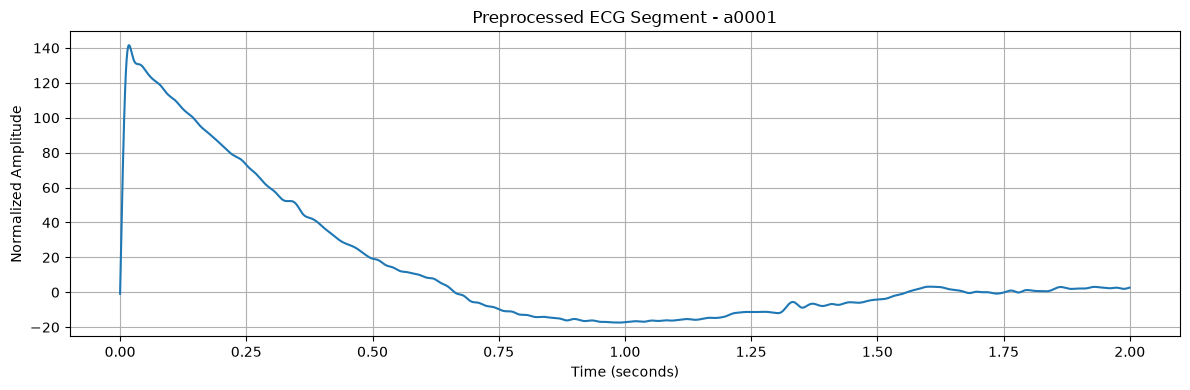

In [46]:
# Cell 43: Visualize one preprocessed 2-second ECG segment

record_id = "a0001"

rec = wfdb.rdrecord(
    os.path.join(PCG_DATASET, record_id)
)

# Find ECG channel
ecg_index = [
    i for i, name in enumerate(rec.sig_name)
    if "ecg" in str(name).lower()
][0]

ecg = rec.p_signal[:, ecg_index].copy()

# Fill missing values
ecg = pd.Series(ecg).interpolate(
    method="linear",
    limit_direction="both"
).to_numpy()

# Band-pass filter: 0.5–40 Hz
nyquist = rec.fs / 2

b, a = butter(
    3,
    [0.5 / nyquist, 40.0 / nyquist],
    btype="bandpass"
)

filtered = filtfilt(b, a, ecg)

# Robust normalization
median = np.median(filtered)
mad = np.median(np.abs(filtered - median))

robust_normalized = (
    (filtered - median) /
    (1.4826 * mad)
)

# First complete 2-second segment
segment_samples = int(2.0 * rec.fs)

segment = robust_normalized[:segment_samples]

time = np.arange(segment_samples) / rec.fs

plt.figure(figsize=(12, 4))
plt.plot(time, segment)

plt.title("Preprocessed ECG Segment - a0001")
plt.xlabel("Time (seconds)")
plt.ylabel("Normalized Amplitude")
plt.grid(True)

plt.tight_layout()
plt.show()

In [48]:
# Cell 45: Fix ECG metadata labels and verify saved dataset

# Load the metadata that was saved before the error
ecg_metadata_path = "../processed/ECG/ecg_metadata.csv"

metadata_df = pd.read_csv(ecg_metadata_path)

print("Columns before fixing:")
print(metadata_df.columns.tolist())

# Check which label column exists
label_columns = [
    col for col in metadata_df.columns
    if col.startswith("label")
]

print("\nLabel-related columns:")
print(label_columns)

# If label_y exists, use it as the correct label
if "label_y" in metadata_df.columns:
    metadata_df["label"] = metadata_df["label_y"]

elif "label_x" in metadata_df.columns:
    metadata_df["label"] = metadata_df["label_x"]

# Remove duplicate label columns
for col in ["label_x", "label_y"]:
    if col in metadata_df.columns:
        metadata_df.drop(columns=[col], inplace=True)

# Convert label to integer
metadata_df["label"] = metadata_df["label"].astype(int)

# Save corrected metadata
metadata_df.to_csv(
    ecg_metadata_path,
    index=False
)

# Load ECG array
ecg_array_path = "../processed/ECG/ecg_segments.npy"

ecg_data = np.load(ecg_array_path)

print("\n" + "=" * 50)
print("ECG DATASET VERIFICATION")
print("=" * 50)

print("ECG array shape :", ecg_data.shape)
print("Metadata shape  :", metadata_df.shape)

print("\nUnique recordings:")
print(metadata_df["recording_id"].nunique())

print("\nLabel distribution:")
print(metadata_df["label"].value_counts())

print("\nSegments per recording:")
print(
    metadata_df.groupby("recording_id")
    .size()
    .describe()
)

print("\nNaN in ECG data:", np.isnan(ecg_data).sum())
print("Inf in ECG data:", np.isinf(ecg_data).sum())

print("\nECG value range:")
print("Min:", ecg_data.min())
print("Max:", ecg_data.max())

print("\nSaved corrected metadata:")
print(ecg_metadata_path)

Columns before fixing:
['recording_id', 'segment_id', 'label_x', 'sample_rate', 'segment_duration', 'original_duration', 'nan_count_before_interpolation', 'label_y']

Label-related columns:
['label_x', 'label_y']

ECG DATASET VERIFICATION
ECG array shape : (6360, 4000)
Metadata shape  : (6360, 7)

Unique recordings:
405

Label distribution:
label
 1    4517
-1    1843
Name: count, dtype: int64

Segments per recording:
count    405.000000
mean      15.703704
std        2.567140
min        4.000000
25%       15.000000
50%       17.000000
75%       17.000000
max       18.000000
dtype: float64

NaN in ECG data: 0
Inf in ECG data: 0

ECG value range:
Min: -52.56292
Max: 210.17441

Saved corrected metadata:
../processed/ECG/ecg_metadata.csv


In [1]:
# Cell 46: Load processed ECG dataset

import numpy as np
import pandas as pd

ECG_ARRAY_PATH = "../processed/ECG/ecg_segments.npy"
ECG_METADATA_PATH = "../processed/ECG/ecg_metadata.csv"

X_ecg = np.load(ECG_ARRAY_PATH)
ecg_metadata = pd.read_csv(ECG_METADATA_PATH)

print("ECG data shape:", X_ecg.shape)
print("Metadata shape:", ecg_metadata.shape)

print("\nLabels:")
print(ecg_metadata["label"].value_counts())

print("\nUnique recordings:",
      ecg_metadata["recording_id"].nunique())

print("\nData type:", X_ecg.dtype)
print("Min:", X_ecg.min())
print("Max:", X_ecg.max())

ECG data shape: (6360, 4000)
Metadata shape: (6360, 7)

Labels:
label
 1    4517
-1    1843
Name: count, dtype: int64

Unique recordings: 405

Data type: float32
Min: -52.56292
Max: 210.17441


In [2]:
#Train/validation /test split
# Cell 47: Recording-level train/validation/test split

from sklearn.model_selection import train_test_split

# Get one label per recording
recording_labels = (
    ecg_metadata[["recording_id", "label"]]
    .drop_duplicates()
    .reset_index(drop=True)
)

print("Total recordings:", len(recording_labels))

# 70% train, 30% temporary
train_records, temp_records = train_test_split(
    recording_labels,
    test_size=0.30,
    stratify=recording_labels["label"],
    random_state=42
)

# Split remaining 30% equally into validation and test
val_records, test_records = train_test_split(
    temp_records,
    test_size=0.50,
    stratify=temp_records["label"],
    random_state=42
)

print("\nRecording split:")
print("Train      :", len(train_records))
print("Validation :", len(val_records))
print("Test       :", len(test_records))

print("\nTrain labels:")
print(train_records["label"].value_counts())

print("\nValidation labels:")
print(val_records["label"].value_counts())

print("\nTest labels:")
print(test_records["label"].value_counts())

Total recordings: 405

Recording split:
Train      : 283
Validation : 61
Test       : 61

Train labels:
label
 1    201
-1     82
Name: count, dtype: int64

Validation labels:
label
 1    44
-1    17
Name: count, dtype: int64

Test labels:
label
 1    43
-1    18
Name: count, dtype: int64


In [3]:
train_ids = set(train_records["recording_id"])
val_ids = set(val_records["recording_id"])
test_ids = set(test_records["recording_id"])

train_mask = ecg_metadata["recording_id"].isin(train_ids)
val_mask = ecg_metadata["recording_id"].isin(val_ids)
test_mask = ecg_metadata["recording_id"].isin(test_ids)

X_train_ecg = X_ecg[train_mask]
X_val_ecg = X_ecg[val_mask]
X_test_ecg = X_ecg[test_mask]

y_train_ecg = ecg_metadata.loc[train_mask, "label"].values
y_val_ecg = ecg_metadata.loc[val_mask, "label"].values
y_test_ecg = ecg_metadata.loc[test_mask, "label"].values

print("Train ECG shape:", X_train_ecg.shape)
print("Validation ECG shape:", X_val_ecg.shape)
print("Test ECG shape:", X_test_ecg.shape)

print("\nTrain labels:")
print(pd.Series(y_train_ecg).value_counts())

print("\nValidation labels:")
print(pd.Series(y_val_ecg).value_counts())

print("\nTest labels:")
print(pd.Series(y_test_ecg).value_counts())

Train ECG shape: (4425, 4000)
Validation ECG shape: (975, 4000)
Test ECG shape: (960, 4000)

Train labels:
 1    3134
-1    1291
Name: count, dtype: int64

Validation labels:
 1    695
-1    280
Name: count, dtype: int64

Test labels:
 1    688
-1    272
Name: count, dtype: int64


In [4]:
#Convert ECG lables to Binary
y_train_binary = (y_train_ecg == 1).astype(np.int32)
y_val_binary = (y_val_ecg == 1).astype(np.int32)
y_test_binary = (y_test_ecg == 1).astype(np.int32)

print("Train binary labels:")
print(pd.Series(y_train_binary).value_counts())

print("\nValidation binary labels:")
print(pd.Series(y_val_binary).value_counts())

print("\nTest binary labels:")
print(pd.Series(y_test_binary).value_counts())

Train binary labels:
1    3134
0    1291
Name: count, dtype: int64

Validation binary labels:
1    695
0    280
Name: count, dtype: int64

Test binary labels:
1    688
0    272
Name: count, dtype: int64


In [5]:
X_train_cnn = X_train_ecg[..., np.newaxis]
X_val_cnn = X_val_ecg[..., np.newaxis]
X_test_cnn = X_test_ecg[..., np.newaxis]

print("Train CNN shape:", X_train_cnn.shape)
print("Validation CNN shape:", X_val_cnn.shape)
print("Test CNN shape:", X_test_cnn.shape)

print("\nData type:", X_train_cnn.dtype)
print("Train min:", X_train_cnn.min())
print("Train max:", X_train_cnn.max())

Train CNN shape: (4425, 4000, 1)
Validation CNN shape: (975, 4000, 1)
Test CNN shape: (960, 4000, 1)

Data type: float32
Train min: -46.116737
Train max: 206.4975


**Build the ECG 1D-CNN baseline**

**This is our ECG-only baseline. It will learn temporal patterns directly from the ECG waveform.**

In [6]:
from tensorflow import keras
from tensorflow.keras import layers

ecg_model = keras.Sequential([
    layers.Input(shape=(4000, 1)),

    layers.Conv1D(32, 7, activation="relu", padding="same"),
    layers.BatchNormalization(),
    layers.MaxPooling1D(2),

    layers.Conv1D(64, 5, activation="relu", padding="same"),
    layers.BatchNormalization(),
    layers.MaxPooling1D(2),

    layers.Conv1D(128, 3, activation="relu", padding="same"),
    layers.BatchNormalization(),
    layers.GlobalAveragePooling1D(),

    layers.Dropout(0.3),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.3),

    layers.Dense(1, activation="sigmoid")
])

ecg_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                      │ (None, 4000, 32)            │             256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization                  │ (None, 4000, 32)            │             128 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling1d (MaxPooling1D)         │ (None, 2000, 32)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1d_1 (Conv1D)                    │ (None, 2000, 64)            │          10,304 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_1                │ (None, 2000, 64)            │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling1d_1 (MaxPooling1D)       │ (None, 1000, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1d_2 (Conv1D)                    │ (None, 1000, 128)           │          24,704 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_2                │ (None, 1000, 128)           │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling1d             │ (None, 128)                 │               0 │
│ (GlobalAveragePooling1D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 1)                   │              65 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 44,481 (173.75 KB)

 Trainable params: 44,033 (172.00 KB)

 Non-trainable params: 448 (1.75 KB)

44,481 total parameters


3 × Conv1D blocks


Batch normalization + pooling


Global Average Pooling


Dense layer → sigmoid output


Suitable for our ECG-only baseline

In [7]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

classes = np.unique(y_train_binary)

class_weights_array = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train_binary
)

class_weights = dict(zip(classes, class_weights_array))

print("Classes:", classes)
print("Class weights:", class_weights)

Classes: [0 1]
Class weights: {np.int32(0): np.float64(1.7137877614252517), np.int32(1): np.float64(0.705966815571155)}


In [8]:
ecg_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        keras.metrics.AUC(name="auc"),
        keras.metrics.Precision(name="precision"),
        keras.metrics.Recall(name="recall")
    ]
)

print("ECG model compiled successfully!")

ECG model compiled successfully!


In [9]:
#Training callbacks
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

early_stopping = EarlyStopping(
    monitor="val_auc",
    mode="max",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

checkpoint = ModelCheckpoint(
    "../processed/ECG/best_ecg_1dcnn.keras",
    monitor="val_auc",
    mode="max",
    save_best_only=True,
    verbose=1
)

print("Callbacks created successfully!")

Callbacks created successfully!


In [11]:
history_ecg = ecg_model.fit(
    X_train_cnn,
    y_train_binary,
    validation_data=(X_val_cnn, y_val_binary),
    epochs=30,
    batch_size=32,
    class_weight=class_weights,
    callbacks=[early_stopping, checkpoint],
    verbose=1
)

Epoch 1/30
139/139 ━━━━━━━━━━━━━━━━━━━━ 0s 258ms/step - accuracy: 0.7444 - auc: 0.8457 - loss: 0.4795 - precision: 0.8969 - recall: 0.7221
Epoch 1: val_auc did not improve from 0.84531
139/139 ━━━━━━━━━━━━━━━━━━━━ 39s 278ms/step - accuracy: 0.7444 - auc: 0.8457 - loss: 0.4795 - precision: 0.8969 - recall: 0.7221 - val_accuracy: 0.7569 - val_auc: 0.8114 - val_loss: 0.4618 - val_precision: 0.8029 - val_recall: 0.8734
Epoch 2/30
139/139 ━━━━━━━━━━━━━━━━━━━━ 0s 262ms/step - accuracy: 0.7525 - auc: 0.8544 - loss: 0.4685 - precision: 0.9015 - recall: 0.7304
Epoch 2: val_auc did not improve from 0.84531
139/139 ━━━━━━━━━━━━━━━━━━━━ 41s 275ms/step - accuracy: 0.7525 - auc: 0.8544 - loss: 0.4685 - precision: 0.9015 - recall: 0.7304 - val_accuracy: 0.7344 - val_auc: 0.7739 - val_loss: 0.6043 - val_precision: 0.7970 - val_recall: 0.8417
Epoch 3/30
139/139 ━━━━━━━━━━━━━━━━━━━━ 0s 261ms/step - accuracy: 0.7557 - auc: 0.8560 - loss: 0.4652 - precision: 0.9027 - recall: 0.7342
Epoch 3: val_auc improv

In [13]:
test_probabilities_ecg = ecg_model.predict(
    X_test_cnn,
    verbose=1
).ravel()

print("Number of test predictions:", len(test_probabilities_ecg))
print("Probability range:",test_probabilities_ecg.min(),"to",test_probabilities_ecg.max())

30/30 ━━━━━━━━━━━━━━━━━━━━ 2s 65ms/step
Number of test predictions: 960
Probability range: 0.012703514 to 0.99944913


In [14]:
from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

segment_auc_ecg = roc_auc_score(
    y_test_binary,
    test_probabilities_ecg
)

test_pred_binary_ecg = (
    test_probabilities_ecg >= 0.5
).astype(np.int32)

segment_accuracy_ecg = accuracy_score(
    y_test_binary,
    test_pred_binary_ecg
)

segment_precision_ecg = precision_score(
    y_test_binary,
    test_pred_binary_ecg
)

segment_recall_ecg = recall_score(
    y_test_binary,
    test_pred_binary_ecg
)

segment_f1_ecg = f1_score(
    y_test_binary,
    test_pred_binary_ecg
)

segment_cm_ecg = confusion_matrix(
    y_test_binary,
    test_pred_binary_ecg
)

print("ECG Segment-Level Results")
print("-------------------------")
print(f"AUC        : {segment_auc_ecg:.4f}")
print(f"Accuracy   : {segment_accuracy_ecg:.4f}")
print(f"Precision  : {segment_precision_ecg:.4f}")
print(f"Recall     : {segment_recall_ecg:.4f}")
print(f"F1 Score   : {segment_f1_ecg:.4f}")

print("\nConfusion Matrix:")
print(segment_cm_ecg)

ECG Segment-Level Results
-------------------------
AUC        : 0.7854
Accuracy   : 0.7490
Precision  : 0.8487
Recall     : 0.7907
F1 Score   : 0.8187

Confusion Matrix:
[[175  97]
 [144 544]]


In [15]:
test_prediction_df_ecg = ecg_metadata.loc[test_mask].copy()

test_prediction_df_ecg["probability"] = test_probabilities_ecg

recording_level_ecg = (
    test_prediction_df_ecg
    .groupby("recording_id")
    .agg(
        true_label=("label", "first"),
        predicted_probability=("probability", "mean"),
        num_segments=("probability", "count")
    )
    .reset_index()
)

print("Number of test recordings:", len(recording_level_ecg))

print("\nTrue labels:")
print(recording_level_ecg["true_label"].value_counts())

print("\nProbability range:")
print(
    recording_level_ecg["predicted_probability"].min(),
    "to",
    recording_level_ecg["predicted_probability"].max()
)

print("\nSegments per recording:")
print(recording_level_ecg["num_segments"].describe())


Number of test recordings: 61

True labels:
true_label
 1    43
-1    18
Name: count, dtype: int64

Probability range:
0.070675366 to 0.97041076

Segments per recording:
count    61.000000
mean     15.737705
std       2.407638
min      10.000000
25%      15.000000
50%      17.000000
75%      17.000000
max      18.000000
Name: num_segments, dtype: float64


In [17]:
recording_true_binary = (
    recording_level_ecg["true_label"] == 1
).astype(np.int32)

recording_probabilities_ecg = (
    recording_level_ecg["predicted_probability"].values
)

recording_auc_ecg = roc_auc_score(
    recording_true_binary,
    recording_probabilities_ecg
)

print(f"ECG Recording-Level AUC: {recording_auc_ecg:.4f}")

ECG Recording-Level AUC: 0.7842


In [18]:
val_prediction_df_ecg = ecg_metadata.loc[val_mask].copy()

val_probabilities_ecg = ecg_model.predict(
    X_val_cnn,
    verbose=1
).ravel()

val_prediction_df_ecg["probability"] = val_probabilities_ecg

val_recording_level_ecg = (
    val_prediction_df_ecg
    .groupby("recording_id")
    .agg(
        true_label=("label", "first"),
        predicted_probability=("probability", "mean"),
        num_segments=("probability", "count")
    )
    .reset_index()
)

print("Validation recordings:", len(val_recording_level_ecg))

print("\nTrue labels:")
print(val_recording_level_ecg["true_label"].value_counts())

print("\nProbability range:")
print(
    val_recording_level_ecg["predicted_probability"].min(),
    "to",
    val_recording_level_ecg["predicted_probability"].max()
)

31/31 ━━━━━━━━━━━━━━━━━━━━ 2s 70ms/step
Validation recordings: 61

True labels:
true_label
 1    44
-1    17
Name: count, dtype: int64

Probability range:
0.02720448 to 0.9203616


In [19]:
from sklearn.metrics import roc_curve

val_true_binary_ecg = (
    val_recording_level_ecg["true_label"] == 1
).astype(np.int32)

val_recording_probabilities_ecg = (
    val_recording_level_ecg["predicted_probability"].values
)

fpr, tpr, thresholds = roc_curve(
    val_true_binary_ecg,
    val_recording_probabilities_ecg
)

youden_index = tpr - fpr

best_idx = np.argmax(youden_index)

best_threshold_ecg = thresholds[best_idx]
best_sensitivity_ecg = tpr[best_idx]
best_specificity_ecg = 1 - fpr[best_idx]
best_youden_ecg = youden_index[best_idx]

print("ECG Validation Threshold")
print("------------------------")
print(f"Best threshold : {best_threshold_ecg:.4f}")
print(f"Sensitivity    : {best_sensitivity_ecg:.4f}")
print(f"Specificity    : {best_specificity_ecg:.4f}")
print(f"Youden Index   : {best_youden_ecg:.4f}")

ECG Validation Threshold
------------------------
Best threshold : 0.5182
Sensitivity    : 0.8182
Specificity    : 1.0000
Youden Index   : 0.8182


In [20]:
test_recording_true = (
    recording_level_ecg["true_label"] == 1
).astype(np.int32)

test_recording_prob = (
    recording_level_ecg["predicted_probability"].values
)

test_recording_pred = (
    test_recording_prob >= best_threshold_ecg
).astype(np.int32)

print("Threshold used:", round(best_threshold_ecg, 4))

print("\nPredicted classes:")
print(pd.Series(test_recording_pred).value_counts())

Threshold used: 0.5182

Predicted classes:
1    43
0    18
Name: count, dtype: int64


In [21]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

test_accuracy_ecg = accuracy_score(
    test_recording_true,
    test_recording_pred
)

test_precision_ecg = precision_score(
    test_recording_true,
    test_recording_pred
)

test_recall_ecg = recall_score(
    test_recording_true,
    test_recording_pred
)

test_f1_ecg = f1_score(
    test_recording_true,
    test_recording_pred
)

test_cm_ecg = confusion_matrix(
    test_recording_true,
    test_recording_pred
)

print("ECG Recording-Level Test Results")
print("--------------------------------")
print(f"AUC         : {recording_auc_ecg:.4f}")
print(f"Accuracy    : {test_accuracy_ecg:.4f}")
print(f"Precision   : {test_precision_ecg:.4f}")
print(f"Sensitivity : {test_recall_ecg:.4f}")
print(f"F1 Score    : {test_f1_ecg:.4f}")

tn, fp, fn, tp = test_cm_ecg.ravel()

test_specificity_ecg = tn / (tn + fp)

print(f"Specificity : {test_specificity_ecg:.4f}")

print("\nConfusion Matrix:")
print(test_cm_ecg)

print("\nTN:", tn)
print("FP:", fp)
print("FN:", fn)
print("TP:", tp)

ECG Recording-Level Test Results
--------------------------------
AUC         : 0.7842
Accuracy    : 0.8033
Precision   : 0.8605
Sensitivity : 0.8605
F1 Score    : 0.8605
Specificity : 0.6667

Confusion Matrix:
[[12  6]
 [ 6 37]]

TN: 12
FP: 6
FN: 6
TP: 37


validation-derived threshold = 0.5182:

Metric	ECG 1D-CNN


Recording-level AUC	0.7842


Accuracy	80.33%


Precision	86.05%


Sensitivity	86.05%

Specificity	66.67%

F1-score	86.05%

                  Predicted
                Normal  Abnormal
Actual Normal      12       6

Actual Abnormal     6      37